[![Mở trong Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/thanhmk/kinhteluong/blob/main/KTL%20T%C3%A0i%20ch%C3%ADnh/Module_7/B2_Ly_thuyet_mang_va_Graphical_LASSO.ipynb)

In [ ]:
# Chuẩn bị môi trường trên Colab (chạy ô này một lần trước khi chạy các ô khác)
import os, urllib.request, urllib.parse

!pip install -q yfinance

print("Bài này không cần tải dữ liệu.")

## KINH TẾ LƯỢNG TÀI CHÍNH
MODULE 7 | BÀI 2

---

# **LÝ THUYẾT MẠNG LƯỚI - Network Theory**

|  |  |
|:---|:---|
|**Thời gian đọc** |60 phút|
|**Kiến thức nền** |OLS, ma trận hiệp phương sai, hồi quy phạt LASSO, Python cơ bản|
|**Từ khóa** |Lý thuyết mạng lưới, lý thuyết đồ thị, ma trận kề, mạng có hướng, mạng vô hướng, hiệu chỉnh Bonferroni, ma trận tương quan riêng phần, ma trận độ chính xác (precision), Graphical LASSO |
|  |  |

## **1. Giới thiệu**
Trong bài này, ta sẽ giới thiệu một cách tiếp cận phân tích hiện đại để hiểu tương tác giữa các thực thể tài chính khác nhau. Đó là lý thuyết mạng lưới. Cụ thể, ta sẽ đưa phân tích hồi quy và chuỗi thời gian đã học ở các bài trước vào phân tích lý thuyết mạng lưới. Trước tiên ta sẽ học kiến thức cơ bản về lý thuyết mạng lưới. Sau đó ta sẽ áp dụng các mô hình hồi quy khác nhau để xây dựng một mạng lưới. Ta sẽ khép lại bài bằng việc học một phương pháp tổng quát và hiệu quả hơn để xây dựng mạng lưới.
## **2. Cơ bản về lý thuyết mạng lưới**
### **2.1 Lý thuyết mạng lưới là gì**
**Lý thuyết mạng lưới (Network Theory)** là phương pháp phân tích để nghiên cứu các mối quan hệ và tương tác giữa các thành phần trong một hệ thống. Lý thuyết mạng lưới cũng gọi là Lý thuyết đồ thị (Graph Theory) trong Toán học. Dù có những khác biệt kỹ thuật giữa lý thuyết mạng lưới và lý thuyết đồ thị, ta sẽ không bàn những khác biệt này trong bài này.
<br>
Lý thuyết mạng lưới có thể phân tích hiệu quả các tương tác phức tạp giữa các thành phần. Nhà toán học Thụy Sĩ Leonard Euler được ghi nhận là người dùng cách tiếp cận này để giải bài toán cầu Konigsberg. Bài toán kinh điển này là tìm một đường đi qua 7 cây cầu ở Konigsberg mà không đi qua cây cầu nào hai lần như trong hình 0 sau (Paoletti, 2011).
<br>
<br>
**Hình 0. Bảy cây cầu ở Konigsberg**
<br>
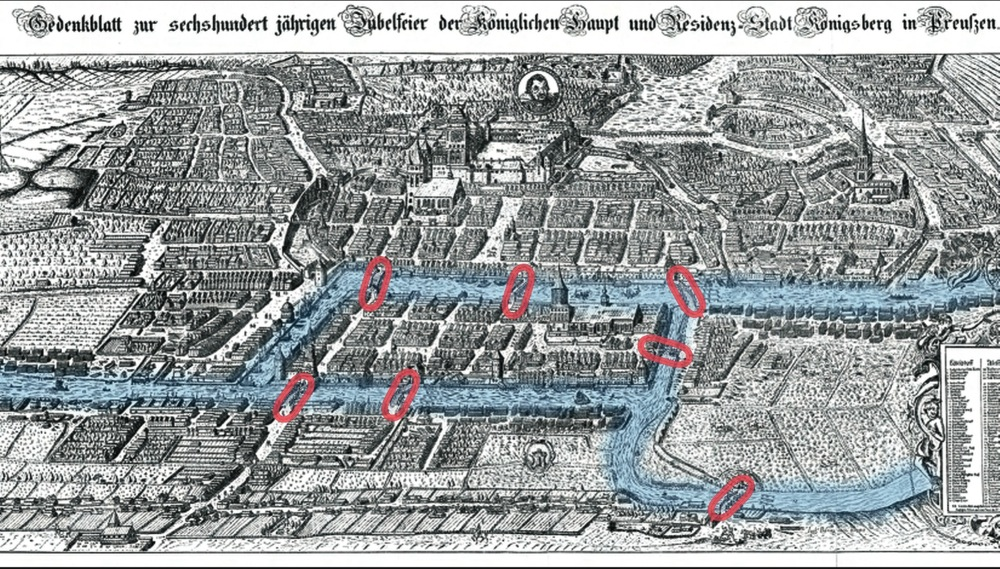
Nguồn: Europe Between East and West
<br>
<br>
Ban đầu, lý thuyết mạng lưới chủ yếu được dùng trong các nghiên cứu mạng xã hội. Ngày nay, nó đã được áp dụng rộng rãi trong nhiều nghiên cứu tài chính, đáng chú ý là quản lý danh mục và quản trị rủi ro. Lý thuyết mạng lưới cung cấp hiểu biết về cách các tài sản tài chính tương tác với nhau trong các kịch bản khác nhau hoặc cách các thực thể tài chính phản ứng trong các sự kiện bất lợi. Một ứng dụng là phân tích rủi ro hệ thống giữa các tổ chức tài chính. Trong một mạng lưới tổ chức tài chính, có các ngân hàng, nhà đầu tư và những người tham gia thị trường tài chính khác. Tất cả đều liên kết với nhau qua giao dịch, đầu tư, cho vay, chuyển tiền và các liên kết tài chính khác. Bằng cách dùng lý thuyết mạng lưới, các nhà nghiên cứu có thể hiểu mức độ liên kết giữa mọi bên tham gia, xác định các đầu mối chính trong hệ thống và thậm chí mô phỏng một yếu tố rủi ro có thể lan nhanh và rộng đến đâu trong toàn mạng lưới.
<br>
<br>
Hãy nhớ rằng mục này nhằm giới thiệu lý thuyết mạng lưới. Bạn sẽ thấy lý thuyết mạng lưới được trình bày rộng rãi trong các khóa học sắp tới: Mô hình hóa ngẫu nhiên, Học máy trong tài chính, Học sâu trong tài chính, Quản lý danh mục và Quản trị rủi ro. Ở các mục tiếp theo, ta sẽ học những kiến thức rất cơ bản về lý thuyết mạng lưới. Sau đó trọng tâm của ta sẽ chuyển sang đưa các phương pháp thống kê ta đã học trong khóa này vào lý thuyết mạng lưới. Ta sẽ khám phá lý thuyết mạng lưới rất sâu trong các khóa quản lý danh mục và quản trị rủi ro.
<br>
<br>
### **2.2 Cấu trúc mạng lưới**
Một mạng lưới là một **hệ thống phức tạp**. Trong một hệ thống phức tạp, có hai loại phần tử chính: **Thành phần** và **Tương tác**. Một thành phần cũng có thể gọi là **Nút (Node)** hay **Đỉnh (Vertex)**. Một tương tác cũng gọi là **Liên kết (Link)** hay **Cạnh (Edge)**. Hình sau minh họa cấu trúc mạng lưới cơ bản.
<br>
<br>
**Hình 1. Minh họa một cấu trúc mạng lưới đơn giản**
<br>
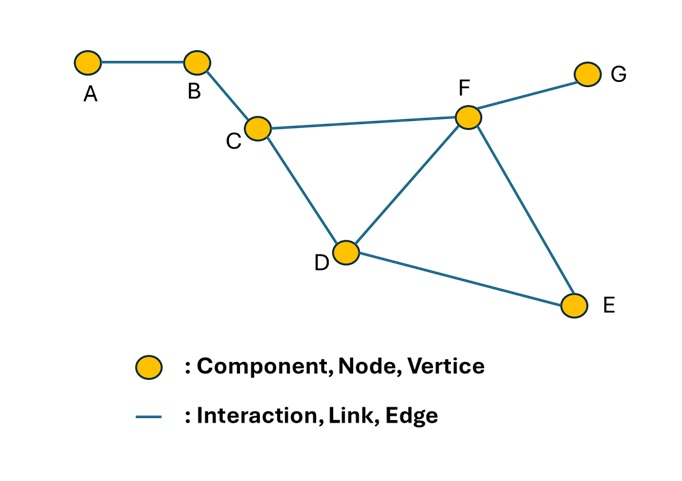
<br>
<br>
Hình 1 cho một biểu diễn đơn giản của cấu trúc mạng lưới. Trong mạng lưới các tổ chức tài chính, các nút có thể đại diện cho ngân hàng thương mại, nhà đầu tư cá nhân, cơ quan quản lý và những người tham gia thị trường tài chính khác. Các cạnh đại diện cho các hoạt động qua đó các thực thể này tương tác.
Ví dụ, nếu nút C là một ngân hàng thương mại và nút B là một nhà đầu tư cá nhân, cạnh giữa chúng có thể đại diện cho hoạt động gửi tiền từ B đến C. Nếu nút F là một hệ thống bù trừ, cạnh giữa các nút C và F đại diện cho việc thanh toán các khoản chuyển tiền giữa C và các ngân hàng thương mại khác trong mạng lưới.
Trong hình này, ta có 7 nút và 8 cạnh. Ta thường dùng **N** để biểu diễn tổng số nút trong mạng lưới và **L** để biểu diễn tổng số cạnh.
Trong một mạng lưới, các tương tác có thể một chiều. Ví dụ, một cá nhân (nút B) có thể gửi tiền vào một ngân hàng thương mại (nút C), nhưng có thể không có tương tác ngược lại tương đương. Ta có thể dùng mũi tên để thể hiện các quan hệ có hướng này.
<br>
<br>
**Hình 2. Minh họa một cấu trúc mạng lưới có hướng**
<br>
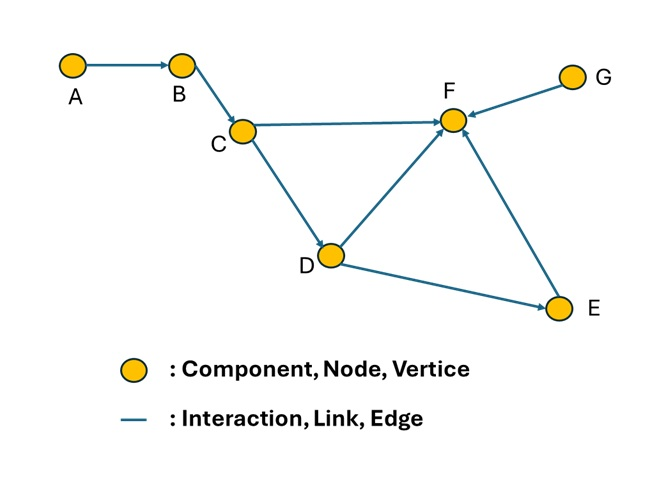
<br>
<br>
Hình 2 cho thấy dòng tương tác giữa mọi nút bằng các đường có mũi tên. Mũi tên chỉ hướng của dòng tương tác. Loại mạng có các liên kết mũi tên trong Hình 2 gọi là **Mạng có hướng (Directed Network)**. Ngược lại, hình 1 biểu diễn một **Mạng vô hướng (Undirected Network)**, trong đó các liên kết không có mũi tên. Với mạng vô hướng, quan hệ giữa các nút là tương hỗ hay hai chiều. Ví dụ, dòng tương tác có thể đi từ nút B đến nút C cũng như từ nút C đến nút B. Vì đặc điểm này, mạng vô hướng cũng **đối xứng**.
<br>
<br>
Với mạng có hướng, có các mũi tên trên các liên kết hay cạnh. **Các mũi tên có thể một chiều hoặc hai chiều.** Các liên kết trong mạng có hướng cũng gọi là **cung (arcs)**.
<br>
<br>
### **2.3 Ma trận kề**
Một cách phổ biến để biểu diễn một mạng lưới dưới dạng dữ liệu là dùng **Ma trận kề (Adjacency Matrix)**. Cách tiếp cận này mô tả cấu trúc mạng lưới trong một ma trận. Hãy xem một số ví dụ về ma trận kề. Trong hình 3, có hai mạng lưới. Một là mạng vô hướng và cái kia là mạng có hướng.
<br>
<br>
**Hình 3. Mạng vô hướng và mạng có hướng**
<br>
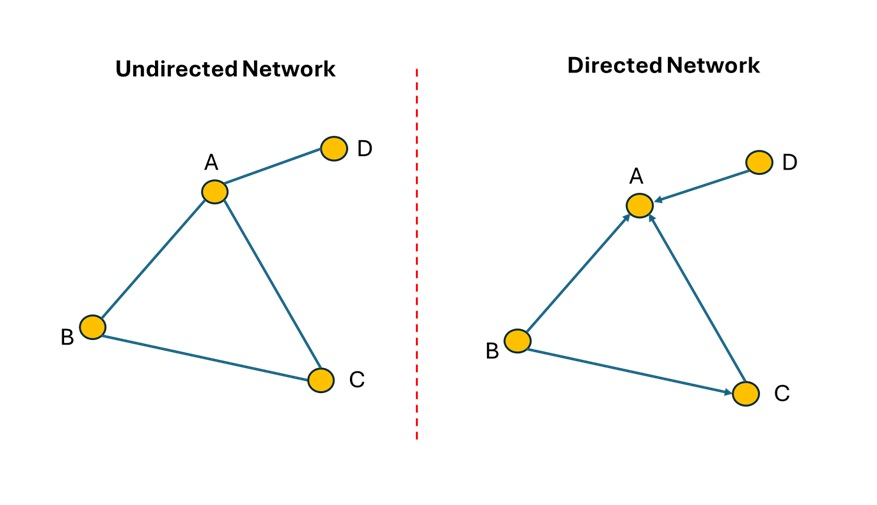
<br>
<br>
Trong hình 3, hai mạng lưới này đều có 4 nút và 4 liên kết. Các ma trận kề của hai mạng lưới nằm trong hình 4 sau.
<br>
<br>
**Hình 4. Ma trận kề cho mạng vô hướng và mạng có hướng**
<br>
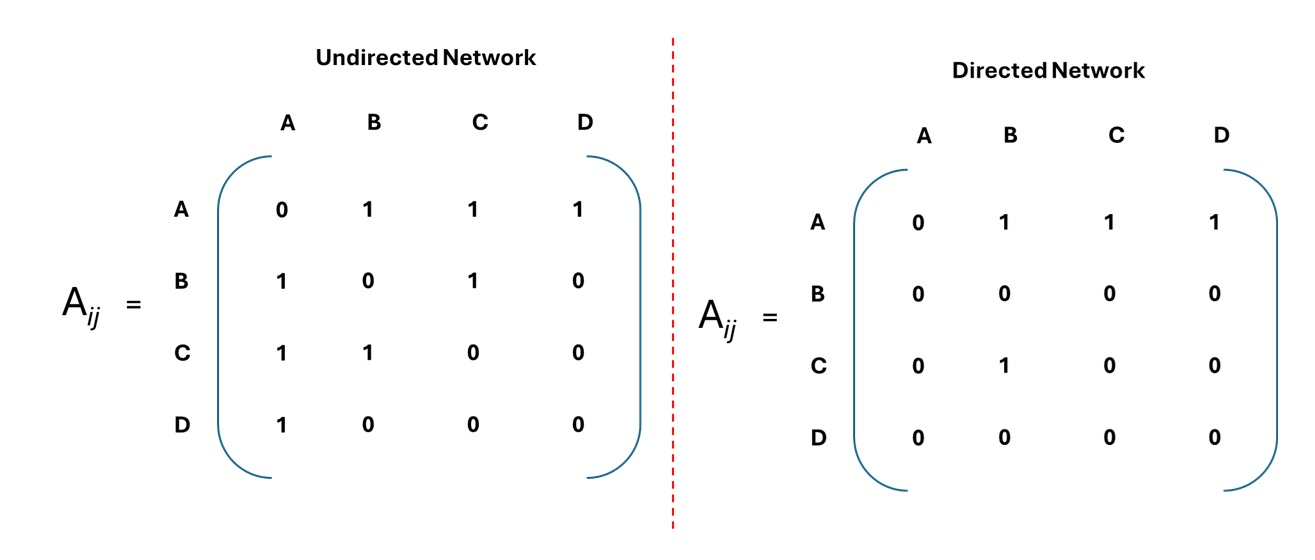
<br>
<br>
Hãy xem ma trận mạng vô hướng bên trái trước. Tên các nút được ghi dọc phía trên và bên trái ma trận cho rõ. Trong một ma trận kề, $A_{ij}$ chỉ phần tử của ma trận kề ở hàng i và cột j. Các giá trị được định nghĩa như sau:
<br>
<br>
$A_{ij}=1$ nếu tồn tại liên kết hướng từ nút j đến nút i
<br>
$A_{ij}=0$ nếu ngược lại
<br>
<br>
Khi đọc một ma trận kề, ta sẽ bắt đầu từ các cột trước. Với ma trận kề của mạng vô hướng, các giá trị trong cột A cho biết có liên kết hướng từ nút A đến nút B, nút C hay nút D không. Trong mạng vô hướng ở hình 4, các liên kết từ nút A đến nút B, nút C và nút D là hai chiều. Do đó các giá trị là 1. Cũng trong mạng này, nút A không có liên kết đến chính nó nên giá trị từ nút A đến nút A là 0. Vậy các giá trị của cột A là (0,1,1,1).
<br>
<br>
Nhìn vào cột D trong mạng vô hướng, liên kết duy nhất tồn tại là liên kết hướng từ nút D đến nút A. Do đó phần tử đầu tiên của cột D là 1. Vì không có liên kết nào khác cho nút D, các phần tử còn lại trong cột D là 0. Vậy các giá trị của cột D là (1,0,0,0). Với cùng logic, ta có thể điền các phần tử của ma trận kề cho mạng có hướng.
<br>
<br>
Một số nhận xét về ma trận kề:
- Các giá trị đường chéo của ma trận kề cho mạng vô hướng đều là 0 nếu mỗi nút không có liên kết đến chính nó.
- Ma trận kề của mạng vô hướng là **đối xứng**.
- Ma trận kề thường **thưa (sparse)**. Lý do là mỗi nút chỉ có một vài liên kết đến một số nút trong mạng. Nghĩa là ma trận kề là ma trận thưa.
- Khi mọi nút trong mạng đều nối với mọi nút khác, mạng này gọi là **đồ thị đầy đủ (complete graph)**.

Các ma trận kề trình bày ở trên chỉ có các phần tử 0 và 1, biểu diễn sự có mặt hay vắng mặt của kết nối. Chúng gọi là **Ma trận kề không trọng số**. Ta có thể nới lỏng giả định này và cho phép các nút được nối có các cường độ kết nối khác nhau. Khi cường độ kết nối giữa các nút trong mạng không chỉ là 1 hoặc 0, mạng này có **Ma trận kề có trọng số**. Hình 5 cho thấy một ví dụ về ma trận kề có trọng số cho một mạng có hướng.
<br>
<br>
**Hình 5. Minh họa một ma trận kề có trọng số**
<br>
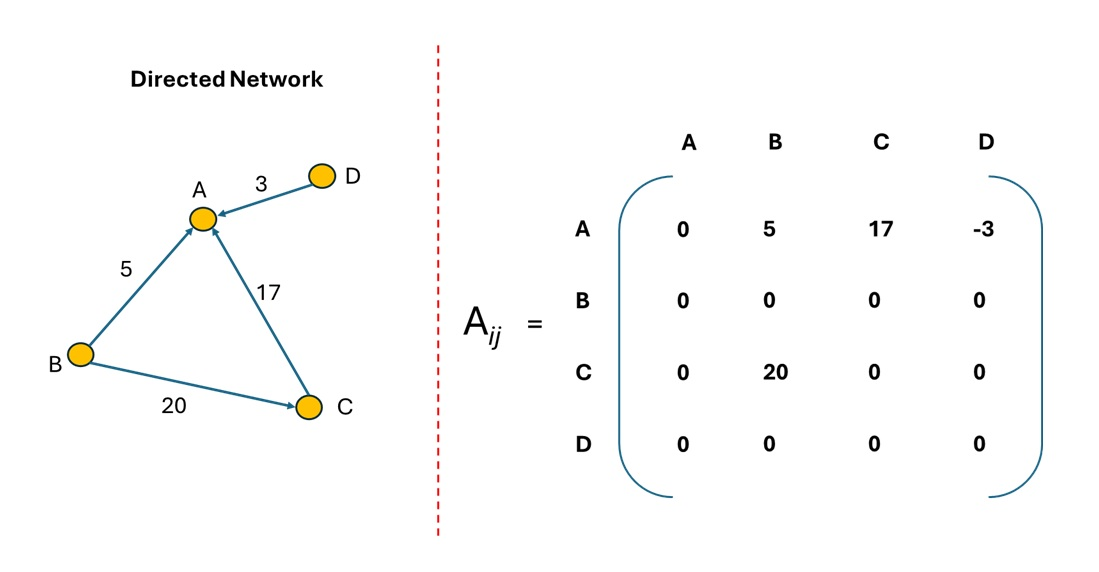
<br>
<br>
Trong ma trận kề có trọng số ở hình 5, các trọng số biểu diễn mức độ mạnh của kết nối giữa các nút chứ không chỉ đơn thuần có kết nối hay không. Các trọng số có thể dương hoặc âm. Ta nên giải thích các trọng số này thế nào? Giả sử A,B,C,D,E đại diện cho các ngân hàng khác nhau trong mạng. Liên kết nghĩa là tiền được chuyển từ ngân hàng này sang ngân hàng khác. Trọng số là lượng tiền chuyển trung bình xảy ra trong một ngày từ ngân hàng này sang ngân hàng kia. Trong trường hợp này, ngân hàng B chuyển tiền cho ngân hàng A trung bình 5 lần một ngày. Nhưng ngân hàng A không chuyển tiền cho ngân hàng B.
<br>
<br>
Hiểu các quan hệ giữa các nút trong mạng có hướng là rất quan trọng cho nhiều phân tích tài chính. Phân tích thường liên quan đến việc xác định các trọng số cho ma trận kề. Ở mục tiếp theo, ta sẽ dùng các phương pháp thống kê đã học ở các bài trước để tìm các trọng số này cho ma trận kề của một mạng có hướng.

## **3. Mô hình dựa trên hồi quy cho mạng tài sản**
Trong mục này, ta sẽ kết hợp các mô hình hồi quy với lý thuyết mạng lưới để hiểu tương tác giữa các tài sản tài chính và các yếu tố khác. Ta sẽ dùng khung mạng tài sản do Konstantinov và Fabozzi(2025) cung cấp để phân tích.

### **3.1 Tổng quan**
Trong một mạng tài chính, các nút thường đã biết, như giá tài sản, tổ chức tài chính, yếu tố kinh tế, v.v. Tuy nhiên các liên kết/cạnh thì chưa biết. Ta không biết quan hệ giữa các nút nhưng ta muốn xây dựng mô hình để giải thích các tương tác. Có một số phương pháp để mô hình hóa các quan hệ này. Một trong các phương pháp là dùng mô hình thống kê. Các mô hình này thường được phát triển bằng dữ liệu chuỗi thời gian. Loại mô hình thống kê phổ biến nhất là mô hình hồi quy. Mục tiêu của mô hình hồi quy là tìm quan hệ giữa các tài sản tài chính và biểu diễn quan hệ dưới dạng mạng lưới.
<br>
<br>
Các mô hình hồi quy thiết lập quan hệ trực tiếp giữa biến phụ thuộc và biến độc lập. Đặc điểm này cung cấp một cách tiếp cận đơn giản để mô hình hóa các liên kết giữa các nút mạng. Trong mạng tài chính, các nút này thường đại diện cho các tài sản tài chính khác nhau. Một lý do chính để dùng mô hình hồi quy cho các tương tác là các hệ số hồi quy đóng vai trò chỉ báo của sự liên hệ giữa các biến. Các hệ số này giúp xác định biến nào nối với biến phụ thuộc và bản chất quan hệ của chúng. Ý nghĩa của các tham số hồi quy đóng vai trò then chốt trong việc xác định các phần tử của ma trận kề. Hiểu quan hệ này giữa hệ số hồi quy và kết nối mạng là thiết yếu để diễn giải đúng kết quả phân tích hồi quy trong bối cảnh xây dựng mạng lưới.
<br>
### **3.2 Dữ liệu**
Như đã nhắc trước đó, các mô hình thống kê cho lý thuyết mạng lưới thường dùng dữ liệu chuỗi thời gian để phân tích. Với các mô hình hồi quy cho mạng tài sản sau đây, ta sẽ dùng giá đóng cửa theo ngày của các cổ phiếu sau từ 2018 đến 2024. Giai đoạn này gồm một số chu kỳ của thị trường chứng khoán Mỹ để dữ liệu có thể đại diện cho các giai đoạn khác nhau của thị trường chứng khoán. Đây là giá của 7 cổ phiếu có trong bộ dữ liệu:
- Apple (AAPL)
- Walmart (WMT)
- Amazon (AMZN)
- General Electric (GE)
- Google (GOOGL)
- JP Morgan (JPM)
- Warner Brothers (WBD)

Ta cũng sẽ đưa các chỉ số chứng khoán hoặc dữ liệu tài sản tài chính khác sau làm các yếu tố cho phân tích:
- Chỉ số S&P 500 (^GSPC)
- Financial Select Sector SPDR Fund (XLF)
- Technology Select Sector SPDR Fund (XLK)
- ETF trái phiếu kho bạc ngắn hạn (SHY)
- Chỉ số đô la Mỹ (DX-Y.NYB)

Sau đó ta sẽ chuyển các giá và chỉ số trên thành lợi suất. Từ các bài trước, ta biết lợi suất có nhiều lợi ích cho phân tích. Trước tiên, hãy nhập một số gói Python và thu thập dữ liệu để phân tích.

In [ ]:
pip install networkx yfinance

In [ ]:
pip install seaborn --upgrade

In [1]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.formula.api import ols
from sklearn.covariance import GraphicalLassoCV
from sklearn.covariance import GraphicalLasso
from sklearn.decomposition import PCA
import yfinance as yf

In [ ]:
# Thu thập dữ liệu cổ phiếu và dữ liệu yếu tố trong 7 năm

# Danh sách tài sản (cổ phiếu)
assets = ['AAPL',   # Apple
          'WMT',    # Walmart
          'AMZN',   # Amazon
          'GE',     # General Electric
          'GOOGL',  # Google
          'JPM',    # JP Morgan
          'WBD']     # Warner Brothers

# Danh sách yếu tố
factors = [
    '^GSPC',   # S&P 500 (yếu tố thị trường)
    'XLF',     # Financial Select Sector SPDR Fund
    'XLK',     # Technology Select Sector SPDR Fund
    'SHY',     # ETF trái phiếu kho bạc ngắn hạn (yếu tố lãi suất)
    'DX-Y.NYB' # Chỉ số đô la Mỹ
]

# Gộp tài sản và yếu tố
tickers = assets + factors

# Tải dữ liệu
data = yf.download(tickers, start="2018-01-01", end="2024-12-31", auto_adjust=False)['Adj Close']

# Tính lợi suất
returns = data.pct_change().dropna()

# Thêm nhãn có ý nghĩa
returns.columns = [
    'Apple', 'Amazon', 'USD', 'GE', 'Google', 'JPMorgan', 'Treasury', 'Warner-Bro', 'Walmart', 'Financial', 'Technology', 'SP500'
]

[**********************58%***                    ]  7 of 12 completed

## **4. Mô hình hồi quy tuyến tính đơn giản cho mạng tài sản**
Trong mục này, ta sẽ bắt đầu bằng việc dùng hồi quy tuyến tính đơn giản (OLS) để mô hình hóa tương tác của 6 lợi suất cổ phiếu (các nút) để xây dựng một mạng tài sản.
Mạng tài sản này sẽ là mạng hai chiều, nghĩa là quan hệ có thể tương hỗ giữa hai nút bất kỳ. Với cổ phiếu i và cổ phiếu j, ta sẽ có một hồi quy trong đó lợi suất của cổ phiếu i là biến phụ thuộc và lợi suất của cổ phiếu j là biến độc lập. Nhưng ta cũng sẽ có một hồi quy khác trong đó lợi suất của cổ phiếu j là biến phụ thuộc và lợi suất của cổ phiếu i là biến độc lập. Các hồi quy sau thể hiện hai hồi quy cho cổ phiếu i và cổ phiếu j.
<br>
<br>
$$R_i = \alpha_{ij} + \beta_{ij}R_j + \varepsilon_i\:\:\:\:\:\:\:\:\:(1)$$
$$R_j = \alpha_{ji} + \beta_{ji}R_i + \varepsilon_j\:\:\:\:\:\:\:\:\:(2)$$
<br>
<br>
Hãy xem hồi quy (1) trước. Theo cách giải thích hồi quy OLS chuẩn, hệ số $\beta_{ij}$ nghĩa là khi $R_j$ tăng một đơn vị, $R_i$ sẽ tăng $\beta_{ij}$ đơn vị. Nếu ước lượng hệ số $\beta_{ij}$ có ý nghĩa thống kê, ta có thể nói quan hệ hồi quy này tồn tại giữa $R_i$ và $R_j$. Trong bối cảnh mạng tài sản, $\beta_{ij}$ cho thấy xu hướng $R_i$ có thể chịu ảnh hưởng bởi $R_j$. Nếu $\beta_{ij}$ có ý nghĩa thống kê, thì sự ảnh hưởng tồn tại. Ta có thể nói $R_i$ phản ứng với $R_j$, hay liên kết đi từ $R_j$ đến $R_i$($R_j$ --> $R_i$). Dù các phương trình trên trông giống CAPM, có những khác biệt đáng kể. Trong CAPM, biến độc lập là biến đại diện thị trường. Nhưng ở đây ta có lợi suất cổ phiếu riêng lẻ làm biến độc lập.
<br>
<br>
Với hồi quy (2), nếu $\beta_{ji}$ có ý nghĩa thống kê, ta có thể suy ra $R_j$ phản ứng với $R_i$. Liên kết giữa hai nút đi từ $R_i$ đến $R_j$($R_i$ --> $R_j$).
<br>
<br>
Bước tiếp theo là kiểm tra giá trị p của hệ số $\beta_{ji}$ về ý nghĩa thống kê. Trong mô hình mạng đơn giản của ta chỉ có hai tài sản, ta có hai mô hình hồi quy. Ta phải tiến hành hai kiểm định đồng thời để kiểm tra ý nghĩa của $\beta_{ij}$ và $\beta_{ji}$. Thường ta đặt ngưỡng giá trị p ở 0.05 cho một kiểm định. Nếu giá trị p của $\beta_{ij}$ nhỏ hơn 0.05, thì $\beta_{ij}$ khác 0 có ý nghĩa thống kê. Tuy nhiên, ta có hai kiểm định trong trường hợp này. Ta sẽ cần điều chỉnh giá trị p để tránh vấn đề kiểm định nhiều lần.
<br>
<br>
Vấn đề kiểm định nhiều lần xuất hiện khi tiến hành nhiều kiểm định thống kê đồng thời mà không điều chỉnh giá trị p, dẫn đến rủi ro dương tính giả bị thổi phồng. Khi dùng ngưỡng giá trị p α = 0.05 cho một kiểm định, bạn chấp nhận 5% khả năng bác bỏ sai giả thuyết không. Tuy nhiên, tỷ lệ sai số này cộng dồn mạnh qua nhiều kiểm định.
Ví dụ, khi tiến hành 5 kiểm định độc lập ở α = 0.05, xác suất có ít nhất một dương tính giả nhảy lên khoảng 23% (1 - (1 - 0.05)^5=0.226). Có nhiều phương pháp điều chỉnh giá trị p cho nhiều kiểm định. Trong bài này, ta sẽ dùng phương pháp Bonferroni. Hãy xem tài liệu đọc bắt buộc để tìm hiểu thêm về phương pháp Bonferroni. Cách phương pháp Bonferroni điều chỉnh ngưỡng giá trị p là chia ngưỡng gốc (giả sử 0.05) cho số kiểm định đã tiến hành. Trong trường hợp mạng hai tài sản đơn giản, ngưỡng giá trị p điều chỉnh sẽ là 0.05/2=0.025. Trong mạng lợi suất 6 cổ phiếu của ta, ngưỡng giá trị p điều chỉnh sẽ là 0.05/30= 0.00167. (Vì sao là 30? Câu hỏi này để lại như một bài tập cho người đọc tự tìm ra).
<br>
<br>
Nếu ta xác nhận $\beta_{ij}$ có ý nghĩa thống kê, ta có thể khẳng định liên kết sau tồn tại: $R_j$ --> $R_i$. Ta cũng có thể điền phần tử trong ma trận kề theo quy tắc sau:
<br>
<br>
$\:\:\:A_{ij} =1\:\:\:\:\:$ nếu $\beta_{ij}$ có ý nghĩa thống kê
<br>
$\:\:\:A_{ij} =0\:\:\:\:\:$ nếu ngược lại
<br>
<br>
Với ma trận kề đã điền, ta có thể vẽ mạng lưới và khảo sát quan hệ giữa các lợi suất tài sản trong mạng tài sản. Đoạn code Python sau thực hiện các bước ta mô tả trong mục này cùng với trực quan hóa mạng tài sản.

In [ ]:
# Tạo dataframe chỉ gồm các tài sản
assets = returns[["Apple","Amazon","GE", "Google","JPMorgan","Warner-Bro","Walmart"]]

# Chạy mạng tài sản dựa trên hồi quy tuyến tính đơn giản
n_assets = len(assets.columns)
adj_matrix = np.zeros((n_assets, n_assets))

# Ngưỡng ý nghĩa (điều chỉnh theo phương pháp Bonferroni)
p_threshold = 0.05/(n_assets*(n_assets-1))

# Duyệt qua mọi cặp tài sản
for i, asset_i in enumerate(assets):
    for j, asset_j in enumerate(assets):
        if i != j:  # Bỏ qua quan hệ với chính nó
            # Chạy hồi quy: asset_i ~ hệ số chặn + asset_j
            model = sm.OLS(assets[asset_i], sm.add_constant(assets[asset_j])).fit()

            # Lấy giá trị p của hệ số góc
            p_value = model.pvalues.iloc[1]

            # Nếu có ý nghĩa, thêm kết nối vào ma trận kề
            adj_matrix[i, j] = 1 if p_value < p_threshold else 0

# Tạo đồ thị có hướng từ ma trận kề
G = nx.from_numpy_array(adj_matrix, create_using=nx.DiGraph)

# Đổi nhãn nút thành tên tài sản
mapping = {i: name for i, name in enumerate(assets)}
G = nx.relabel_nodes(G, mapping)

# Trực quan hóa mạng lưới
plt.figure(figsize=(10, 8))
pos = nx.spring_layout(G, seed=42)
nx.draw(G, pos,
        node_color='lightblue',
        node_size=500,
        with_labels=True,
        font_size=10,
        edge_color='gray',
        arrows=True,
        arrowsize=15)
plt.title('Mạng tài sản dựa trên hồi quy tuyến tính đơn giản')
plt.show()

In [ ]:
adj_matrix

Trong mạng tài sản dựa trên hồi quy tuyến tính đơn giản ở trên, ta thấy mọi lợi suất cổ phiếu đều nối với các lợi suất cổ phiếu khác trong mạng này. Đây là mạng có hướng. Từ đồ thị, quan hệ giữa hai lợi suất tài sản bất kỳ đều hai chiều. Ta cũng có thể in ma trận kề ra để xác nhận phát hiện này. Mạng tài sản dựa trên hồi quy tuyến tính này có vẻ không cung cấp nhiều thông tin. Ta phải thử một cấu trúc mô hình hồi quy khác. Ta sẽ thử mạng tài sản dựa trên hồi quy phi tuyến.
<br>
## **5. Mô hình hồi quy phi tuyến cho mạng tài sản**
Trong mục này, ta kiểm thử mạng tài sản dựa trên hồi quy phi tuyến. Ta đã học rằng mạng tài sản dựa trên hồi quy tuyến tính không cung cấp nhiều thông tin về quan hệ giữa 6 lợi suất cổ phiếu. Một cách ta có thể điều chỉnh mô hình hồi quy là thêm biến độc lập bình phương để làm hồi quy phi tuyến. Theo ví dụ hai lợi suất cổ phiếu ở mục trước, các hồi quy có thể điều chỉnh như sau:
<br>
<br>
$$R_i = \alpha_{ij} + \beta_{ij}R_j + \gamma_{ij}R_j^2 + \varepsilon_i\:\:\:\:\:\:\:\:\:(3)$$
$$R_j = \alpha_{ji} + \beta_{ji}R_i +  \gamma_{ji}R_i^2 +\varepsilon_j\:\:\:\:\:\:\:\:\:(4)$$
<br>
<br>
Với phần điều chỉnh các hồi quy, trọng tâm của ta vẫn là $\beta$ để hiểu phần tuyến tính của quan hệ giữa các lợi suất cổ phiếu có tồn tại không.
Đoạn code Python sau thực hiện mô hình mạng tài sản dựa trên hồi quy phi tuyến cho 6 lợi suất cổ phiếu.

In [ ]:
# Chạy mạng tài sản dựa trên hồi quy phi tuyến
n_assets = len(assets.columns)
adj_matrix = np.zeros((n_assets, n_assets))

# Ngưỡng ý nghĩa (có thể điều chỉnh)
p_threshold = 0.05/(n_assets*(n_assets-1))

# Duyệt qua mọi cặp tài sản
for i, asset_i in enumerate(assets):
    for j, asset_j in enumerate(assets):
        if i != j:  # Bỏ qua quan hệ với chính nó
            # Tạo số hạng bình phương
            indep = pd.concat([assets[asset_j],assets[asset_j]**2], axis = 1)
            # Chạy hồi quy với hệ số chặn, số hạng gốc và số hạng bình phương
            X = sm.add_constant(indep)
            model = sm.OLS(assets[asset_i], X).fit()

            # Lấy giá trị p của hệ số góc
            p_value = model.pvalues.iloc[1]

            # Nếu có ý nghĩa, thêm kết nối vào ma trận kề
            adj_matrix[i, j] = 1 if p_value < p_threshold else 0

# Tạo đồ thị có hướng từ ma trận kề
G = nx.from_numpy_array(adj_matrix, create_using=nx.DiGraph)

# Đổi nhãn nút thành tên tài sản
mapping = {i: name for i, name in enumerate(assets)}
G = nx.relabel_nodes(G, mapping)

# Tạo và trực quan hóa mạng lưới
plt.figure(figsize=(10, 8))
pos = nx.spring_layout(G, seed=42)
nx.draw(G, pos,
        node_color='lightblue',
        node_size=500,
        with_labels=True,
        font_size=10,
        edge_color='gray',
        arrows=True,
        arrowsize=15)
plt.title('Mạng tài sản dựa trên hồi quy phi tuyến')
plt.show()

In [ ]:
adj_matrix

Xem kết quả đồ thị ở trên từ mạng tài sản dựa trên hồi quy phi tuyến, ta không thấy khác biệt so với đồ thị từ các mô hình hồi quy tuyến tính. Rõ ràng, dùng lợi suất bình phương của cổ phiếu không cải thiện được lợi suất của cổ phiếu; nên tính phi tuyến này không giúp ích cho hồi quy. Ở mục tiếp theo, ta sẽ đưa một số hạng mới vào các mô hình hồi quy để xem phần điều chỉnh mới này có cung cấp thêm hiểu biết về mạng tài sản không.
<br>
## **6. Mô hình hồi quy tuyến tính có biến gây nhiễu (confounder) cho mạng tài sản**
Bây giờ, hãy nghĩ sâu hơn một chút về mạng tài sản hai cổ phiếu của ta. Ở các mục trước, ta chỉ dùng lợi suất của hai cổ phiếu này để xác định quan hệ của chúng. Đôi khi, cách thiết lập mô hình đó có thể không đủ liên hệ kinh tế. Có thể có trường hợp lý do hai cổ phiếu tương quan là vì cả hai đều chịu ảnh hưởng của một yếu tố chung không có trong mô hình. Trong trường hợp của ta, một chỉ số cổ phiếu có thể là yếu tố chung ảnh hưởng đến cả hai lợi suất cổ phiếu. Do đó, việc đặc tả mô hình hồi quy sai mà không có các liên hệ kinh tế được suy xét kỹ có thể tạo ra các quan hệ giữa biến giả mà thực tế không tồn tại.
<br>
<br>
Để xử lý vấn đề quá khớp hoặc quan hệ giả sinh ra từ các mô hình hồi quy, các nhà nghiên cứu đề xuất đưa các yếu tố vào làm biến gây nhiễu trong các mô hình (López de Prado, 2003). Tiêu chí then chốt để chọn một biến gây nhiễu là biến gây nhiễu nên tương quan với (các) biến độc lập. Biến gây nhiễu cũng nên có quan hệ nhân quả với biến phụ thuộc vì ta đang phân tích mạng tài sản có hướng. Giả sử $R_{C}$ là lợi suất của biến gây nhiễu, ta có thể đưa $R_{C}$ vào các mô hình hồi quy của ta như sau:
<br>
<br>
$$R_i = \alpha_{ij} + \beta_{ij}R_j + \rho_{ij} R_{C}+\varepsilon_i\:\:\:\:\:\:\:\:\:(5)$$
$$R_j = \alpha_{ji} + \beta_{ji}R_i +  \rho_{ji} R_{C} +\varepsilon_j\:\:\:\:\:\:\:\:\:(6)$$
<br>
<br>
Việc chọn biến gây nhiễu phụ thuộc vào phân tích kinh tế lượng. Trong trường hợp của ta, vì các tài sản của ta đều là cổ phiếu, chỉ số S&P 500 là lựa chọn tốt làm biến gây nhiễu vì nó đại diện cho mức độ tiếp xúc chung với thị trường cổ phiếu.
<br>
<br>
Ta có thể chạy lại các mô hình hồi quy tuyến tính với lợi suất S&P 500, rồi xem lại kết quả. Ta vẫn tập trung vào các ước lượng $\beta$ từ các mô hình hồi quy.

In [ ]:
# Chạy mạng tài sản dựa trên hồi quy tuyến tính có biến gây nhiễu
n_assets = len(assets.columns)
adj_matrix = np.zeros((n_assets, n_assets))
SP500 = returns["SP500"]


# Ngưỡng ý nghĩa (có thể điều chỉnh)
p_threshold = 0.05/(n_assets*(n_assets-1))

# Duyệt qua mọi cặp tài sản
for i, asset_i in enumerate(assets):
    for j, asset_j in enumerate(assets):
        if i != j:  # Bỏ qua quan hệ với chính nó
            # Tạo số hạng bình phương
            indep = pd.concat([assets[asset_j], SP500], axis = 1)
            # Chạy hồi quy với số hạng thứ hai
            X = sm.add_constant(indep)
            model = sm.OLS(assets[asset_i], X).fit()

            # Lấy giá trị p của hệ số góc
            p_value = model.pvalues.iloc[1]

            # Nếu có ý nghĩa, thêm kết nối vào ma trận kề
            adj_matrix[i, j] = 1 if p_value < p_threshold else 0

# Tạo đồ thị có hướng từ ma trận kề
G = nx.from_numpy_array(adj_matrix, create_using=nx.DiGraph)

# Đổi nhãn nút thành tên tài sản
mapping = {i: name for i, name in enumerate(assets)}
G = nx.relabel_nodes(G, mapping)

# Tạo và trực quan hóa mạng lưới
plt.figure(figsize=(10, 8))
pos = nx.spring_layout(G, seed=42)
nx.draw(G, pos,
        node_color='lightblue',
        node_size=500,
        with_labels=True,
        font_size=10,
        edge_color='gray',
        arrows=True,
        arrowsize=15)
plt.title('Mạng tài sản dựa trên hồi quy tuyến tính với S&P500 làm biến gây nhiễu')
plt.show()

Bằng cách kiểm soát biến gây nhiễu trong các mô hình hồi quy của ta, mạng tài sản mới cho thấy một số thông tin thú vị. Từ đồ thị, ta thấy JPMorgan và GE là hai cổ phiếu duy nhất có quan hệ hai chiều với mọi cổ phiếu khác; do đó, JPMorgan và GE có thể coi là hai đầu mối (hub) trong mạng tài sản này. Ta đều biết JPMorgan là một tổ chức tài chính nên nó hẳn có quan hệ kinh doanh với các công ty khác. Còn GE, nó cũng có mảng tài chính trong hoạt động kinh doanh và có thể coi là một tổ chức tài chính. Quan sát thú vị tiếp theo là cả ba cổ phiếu công nghệ (Apple, Amazon và Google) cũng có quan hệ hai chiều. Phát hiện này cho thấy các cổ phiếu trong ngành công nghệ có thể liên kết rất chặt với nhau. Quan sát thú vị cuối cùng cần chỉ ra là lợi suất cổ phiếu Warner Brothers và lợi suất cổ phiếu Walmart không nối với nhau sau khi đưa lợi suất chỉ số S&P 500 vào mô hình. Điều này cho biết cả hai lợi suất cổ phiếu không tương quan trực tiếp sau khi tính đến lợi suất chỉ số S&P 500. Ta nói lợi suất cổ phiếu Warner Brothers và lợi suất cổ phiếu Walmart **độc lập có điều kiện (conditionally independent)**. Tính độc lập có điều kiện cũng xảy ra ở các cặp khác.
<br>
<br>
Cho đến giờ, ta đã dùng phân tích hồi quy để mô hình hóa các liên kết giữa các nút trong mạng lưới. Khi tiến hành phân tích hồi quy trong khung mạng lưới, ta vẫn cần chú ý các mục sau.
- kiểm tra tính tuyến tính của bộ dữ liệu
- giá trị ngoại lai ở các biến phụ thuộc
- điểm đòn bẩy (leverage) ở các biến độc lập
- phương sai thay đổi của các số hạng sai số
- đa cộng tuyến giữa các biến độc lập và biến gây nhiễu

## **7. Mô hình LASSO cho tài sản và yếu tố**
#### ***7.1 Tổng quan***
Mục trước đã cho thấy sức mạnh của việc thêm một biến gây nhiễu vào mạng tài sản. Bây giờ ta đối mặt một thách thức mới: nếu tồn tại nhiều biến gây nhiễu tiềm năng, đều có cơ sở kinh tế thì sao? Ta cần một phương pháp hiệu quả hơn để kiểm thử các biến gây nhiễu này trong các mô hình hồi quy khi ước lượng cấu trúc mạng. Trong mục này, ta sẽ gọi các biến gây nhiễu này là **Yếu tố (Factors)** và giới thiệu **Graphical LASSO** (Graphical Least Absolute Shrinkage and Selection Operator).
<br>
<br>
Mục tiêu của ta vẫn như cũ: xác định các quan hệ trực tiếp giữa các tài sản trong khi kiểm soát các yếu tố khác. Các quan hệ trực tiếp này hình thành nền tảng của mạng tài sản và yếu tố của ta. **Tương quan riêng phần (Partial correlation)** là thước đo phù hợp để đánh giá các quan hệ trực tiếp này. Khác với tương quan chuẩn, tương quan riêng phần định lượng quan hệ giữa hai biến trong khi kiểm soát tác động của các biến khác. Cách tiếp cận này giúp xác định các kết nối thực sự trực tiếp giữa các tài sản, lọc bỏ các quan hệ gián tiếp xảy ra qua các tài sản trung gian, nhờ đó cho bức tranh rõ hơn về cấu trúc mạng nền tảng trong thị trường tài chính. Hãy xem tài liệu đọc bắt buộc "Phân phối có điều kiện" để biết thêm về tương quan riêng phần.
<br>
<br>
Trong bối cảnh mạng lưới, ta sẽ cần có một ma trận tương quan riêng phần để mô tả các tương quan riêng phần cho mọi tài sản và yếu tố trong mạng. Từ đó ta có thể xây dựng các liên kết giữa các nút. Trong thị trường tài chính thực, không phải mọi tài sản và yếu tố đều tương quan riêng phần với nhau. Nhiều tương quan riêng phần có thể bằng 0. Để chuyển quan sát này sang ma trận tương quan riêng phần, ta có thể nói ma trận tương quan riêng phần là **thưa (sparse)**. Để xác định tính thưa trong ma trận tương quan riêng phần, ta có thể dùng LASSO hay phạt L1 để áp ràng buộc khi ước lượng ma trận tương quan riêng phần. Phạt lasso áp đặt tính thưa này bằng cách co nhiều tương quan riêng phần về đúng bằng không. Khi tương quan riêng phần của hai biến bằng 0, ta nói hai biến này độc lập có điều kiện.
<br>
<br>
#### ***7.2 Mô hình Graphical LASSO***
Trong mô hình Graphic LASSO, có $p$ biến ngẫu nhiên trong bộ dữ liệu $\textbf{X}$ tuân theo phân phối chuẩn đa biến như sau:
 $$\textbf{X} = (X_{1}, X_{2},...,X_{p})\sim MVP(\mu,\Sigma)$$
<br>
<br>
Hãy định nghĩa $\Theta=\Sigma^{-1}$, trong đó $\Theta$ là nghịch đảo của ma trận hiệp phương sai. $\Theta$ gọi là **Ma trận độ chính xác (Precision Matrix)**. Các phần tử của ma trận độ chính xác này tỷ lệ với ma trận tương quan riêng phần. Bằng cách ước lượng ma trận độ chính xác, ta có thể xác định các tương quan riêng phần cần thiết để xây dựng mạng lưới.
<br>
<br>
Để đưa tính thưa của các ma trận tương quan riêng phần vào mạng tài sản và yếu tố, ta áp dụng phạt LASSO vào mô hình. Friedman và cộng sự (2008) đề xuất một phương pháp hiệu quả để giải ma trận hiệp phương sai nghịch đảo trong mô hình Graphical LASSO bằng cách cực đại hóa hàm log hợp lý có phạt sau theo vectơ trung bình $\mu$:
<br>
<br>
$$log\text{ }det(\Theta)-trace(S\Theta)-\rho\left\| \Theta \right\|_{1}$$
<br>
trong đó 
<br>
$\Theta$ là nghịch đảo của ma trận hiệp phương sai
<br>
$S$ là ma trận hiệp phương sai mẫu
<br>
$\rho$ là tham số phạt để kiểm soát tính thưa
<br>
$\left\| \Theta \right\|_{1}$ là chuẩn L1, tổng các giá trị tuyệt đối của các phần tử của $\Theta$
<br>
<br>
Tham số $\rho$ rất quan trọng: tăng $\rho$ cho mạng thưa hơn bằng cách ép nhiều phần tử của $\Theta$ về không, từ đó làm các tương quan riêng phần tương ứng bằng không. Việc chọn giá trị $\rho$ phù hợp đòi hỏi cân nhắc cẩn thận. Nếu $\rho$ quá cao, ta sẽ không có kết nối nào giữa các tài sản; nếu $\rho$ quá thấp, mọi tài sản sẽ đều nối với nhau, làm mạng lưới không còn thông tin. Trong ứng dụng của ta, ta sẽ dùng kiểm định chéo (cross-validation) để xác định $\rho$ tối ưu.
<br>
<br>
#### ***7.3 Ứng dụng***
Trong mục này, ta sẽ áp dụng mô hình Graphical LASSO cho bộ dữ liệu mô tả ở Mục 3.2 để xây dựng một mạng tài sản và yếu tố. Ta sẽ dùng cả 7 lợi suất cổ phiếu ta đã dùng ở các mục trước. Ta cũng sẽ thêm ETF S&P500, ETF trái phiếu kho bạc, ETF ngành tài chính, ETF công nghệ và Chỉ số đô la Mỹ làm các yếu tố vào mô hình. Mô hình này sẽ minh họa cách ma trận độ chính xác có thể tiết lộ cấu trúc nền tảng của thị trường tài chính trong khi kiểm soát các yếu tố chung.
<br>
<br>
Trước tiên, hãy chuẩn hóa toàn bộ dữ liệu lợi suất cổ phiếu và yếu tố.

In [ ]:
# Chuẩn hóa dữ liệu
standardized_returns = (returns - returns.mean()) / returns.std()

Tiếp theo, ta sẽ dùng phương pháp kiểm định chéo để tìm mức $\rho$ tối ưu cho phân tích.

In [ ]:
# Tạo dải giá trị rho để thử
rhos = np.linspace(0.3, 1, 100)

# Dùng GraphicalLassoCV để tìm alpha tốt nhất
model_cv = GraphicalLassoCV(alphas=rhos, cv=5, tol=1e-2, max_iter=400)
model_cv.fit(standardized_returns)

#best_rho = 0.3
best_rho = model_cv.alpha_
print(f"ρ tốt nhất: {best_rho}")

Với $\rho$ tối ưu đã có, bây giờ ta có thể khớp mô hình graphical LASSO và ước lượng nghịch đảo của ma trận hiệp phương sai. Sau đó ta có thể tính ma trận tương quan riêng phần.

In [ ]:
# Khớp mô hình với alpha tốt nhất
model = GraphicalLasso(alpha=best_rho, max_iter=400, tol=1e-2)
model.fit(standardized_returns)

# Lấy ma trận độ chính xác (hiệp phương sai nghịch đảo)
precision_matrix = model.precision_

# Chuyển ma trận độ chính xác thành ma trận tương quan riêng phần để dễ diễn giải
d = np.sqrt(np.diag(precision_matrix))
partial_corr = -precision_matrix / np.outer(d, d)
np.fill_diagonal(partial_corr, 0)  # Bỏ các vòng tự nối
partial_corr

Khi có ma trận tương quan riêng phần, ta sẽ dùng nó để tạo ma trận kề. Ta dùng quy tắc: nếu giá trị tuyệt đối của tương quan riêng phần giữa hai nút lớn hơn 0, phần tử của ma trận kề sẽ là 1. Nếu không, phần tử sẽ là 0.

In [ ]:
# Tạo ma trận kề bằng một ngưỡng
threshold = 0.0  # Điều chỉnh khi cần
adjacency = (np.abs(partial_corr) > threshold).astype(int)
adjacency

Bây giờ, ta đã sẵn sàng vẽ mạng lưới!

In [ ]:
# Tạo mạng lưới
G = nx.from_numpy_array(adjacency)

# Đổi nhãn nút thành tên tài sản và yếu tố
mapping = {i: name for i, name in enumerate(returns.columns)}
G = nx.relabel_nodes(G, mapping)

# Gán loại cho các nút
node_types = {
    'Apple':'Asset',
    'Amazon':'Asset',
    'USD':'Factor',
    'GE':'Asset',
    'Google':'Asset',
    'JPMorgan':'Asset',
    'Treasury':'Factor',
    'Warner-Bro':'Asset',
    'Walmart':'Asset',
    'Financial':'Factor',
    'Technology':'Factor',
    'SP500':'Factor',
}

nx.set_node_attributes(G, node_types, 'type')

# Vẽ đồ thị mạng lưới
plt.figure(figsize=(14, 10))

# Dùng màu khác nhau cho tài sản và yếu tố
node_colors = ['skyblue' if G.nodes[name]['type'] == 'Asset' else 'orange' for name in G.nodes()]

# Tạo bố cục
pos = nx.spring_layout(G, seed=42)

# Vẽ mạng lưới
nx.draw(G, pos,
        with_labels=True,
        node_size=500,
        node_color=node_colors,
        font_size=10,
        font_weight='bold',
        edge_color='gray',
        arrows=True,
        arrowsize=15)

# Thêm chú giải
asset_patch = plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='skyblue',
                       markersize=15, label='Tài sản')
factor_patch = plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='orange',
                        markersize=15, label='Yếu tố')
plt.legend(handles=[asset_patch, factor_patch], loc='upper right')

plt.title('Mạng yếu tố-tài sản qua Graphical LASSO', fontsize=16)
plt.show()

Từ đồ thị mạng tài sản và yếu tố ở trên, ta có một số quan sát thú vị.
<br>
1. ETF S&P500, ETF ngành tài chính và ETF công nghệ chiếm vị trí trung tâm của mạng lưới, thể hiện sự kết nối cao của chúng với các cổ phiếu khác.
2. ETF trái phiếu kho bạc và chỉ số USD chỉ nối với nhau và tạo thành một cụm riêng, cho thấy chúng thiếu kết nối với 7 cổ phiếu.
3. Ba lợi suất cổ phiếu công nghệ (Apple, Amazon và Google) tạo thành một cụm và nối với nhau. Chúng cũng nối với ETF công nghệ và chỉ số S&P500.
4. JP Morgan, GE và ETF ngành tài chính đều nối với nhau và tạo thành một cụm tài chính.
5. Walmart chỉ nối với chỉ số S&P500.

Với các quan sát trên, ta thấy 3 cổ phiếu công nghệ tương quan với nhau. Đây có thể là vấn đề nếu cả 3 cổ phiếu đều chiếm tỷ trọng lớn trong một danh mục. Nhà quản lý danh mục có thể phải xem lại phân bổ tài sản và điều chỉnh tỷ trọng nắm giữ 3 cổ phiếu công nghệ này. Một hiểu biết khác từ đồ thị mạng là ETF trái phiếu kho bạc và USD không tương quan với thị trường cổ phiếu. Chúng có thể là các lựa chọn đầu tư thay thế tốt để thêm vào danh mục toàn cổ phiếu nhằm đa dạng hóa rủi ro thị trường cổ phiếu.
<br>
<br>
#### ***7.4 So sánh mạng lưới với ma trận tương quan và PCA***
Ta đã phân tích kết quả mạng tài sản-yếu tố ở mục trước. Dù mạng dựa trên Graphical LASSO tiết lộ các phụ thuộc có điều kiện giữa tài sản và yếu tố, sẽ thú vị khi so sánh các phát hiện này với phân tích tương quan truyền thống và Phân tích thành phần chính (PCA). Hãy bắt đầu với phân tích tương quan. Ta sẽ tạo ma trận tương quan và vẽ bản đồ nhiệt để phân tích.

In [ ]:
# Tính ma trận tương quan cho lợi suất cổ phiếu đã chuẩn hóa và vẽ bản đồ nhiệt tương quan
corr_matrix = standardized_returns.corr()

# Tạo bản đồ nhiệt
plt.figure(figsize=(10, 8))  # Điều chỉnh kích thước hình khi cần
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Bản đồ nhiệt tương quan lợi suất cổ phiếu đã chuẩn hóa')
plt.show()

Từ bản đồ nhiệt tương quan ở trên, ta thấy những kết luận tương tự như ta thu được từ mạng tài sản và yếu tố. Điều thú vị là mạng tài sản và yếu tố cho các kết nối thưa hơn trong mạng Graphical LASSO. Trong bản đồ nhiệt này, ta thấy các tương quan khá giữa các cặp Apple và ETF ngành tài chính, JPMorgan và ETF công nghệ, và Google và ETF ngành tài chính. Tuy nhiên, ta không thấy các liên kết này trong mạng tài sản-yếu tố. Điều này gợi ý rằng các cặp có tương quan cao bổ sung từ bản đồ nhiệt được trung gian qua các biến khác trong mạng tài sản-yếu tố.
<br>
<br>
Tiếp theo, hãy xem phân tích PCA.

In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=12)
pca.fit(standardized_returns)

# Lấy tỷ lệ phương sai và tỷ lệ phương sai tích lũy
pr_var = pca.explained_variance_ratio_
cum_pr = np.cumsum(pca.explained_variance_ratio_)
ind = ["Tỷ lệ phương sai", "Tỷ lệ phương sai tích lũy"]
cols = ["PC1", "PC2", "PC3", "PC4", "PC5", "PC6", "PC7", "PC8", "PC9", "PC10", "PC11", "PC12"]
pd.DataFrame(np.vstack((pr_var, cum_pr)), ind, columns=cols)

Từ kết quả PCA ở trên, ta thấy thành phần thứ nhất chiếm 47% biến thiên dữ liệu. 3 thành phần đầu chiếm gần 70% biến thiên dữ liệu. Nghĩa là có các yếu tố tập trung trong bộ dữ liệu của ta. Bây giờ hãy xem các hệ số tải.

In [ ]:
# Hệ số (hệ số tải) của 11 thành phần chính
pc_res = pd.DataFrame(pca.components_.T, index=list(standardized_returns.columns), columns=cols)
pc_res

Bảng hệ số tải ở trên cho ta một số hiểu biết chính:

1. Các phần tử chính trong PC1 là ETF S&P500, ETF công nghệ và ETF ngành tài chính. Nó biểu diễn yếu tố thị trường cổ phiếu chung
2. Các phần tử chính trong PC2 là chỉ số USD và ETF trái phiếu kho bạc. Thành phần này nắm bắt cụm tương tự của chỉ số USD và ETF trái phiếu kho bạc trong mạng tài sản và yếu tố
3. PC3 có vẻ là thành phần có tác động âm lên ngành tài chính nhưng tác động dương lên ngành công nghệ.

Nhìn chung, kết quả từ PCA bổ sung cho kết quả từ mạng tài sản-yếu tố. Phân tích mạng cho ta biết các kết nối giữa các tài sản và yếu tố trong khi PCA cho hiểu biết về các động lực chung có thể tạo nên các phụ thuộc này.

## **8. Kết luận**
Trong bài này, trước tiên ta giới thiệu lý thuyết mạng lưới là gì. Ta đã bàn kiến thức cơ bản của lý thuyết mạng lưới. Sau đó ta minh họa cách đưa hồi quy vào lý thuyết mạng lưới để phân tích sự liên kết giữa các cổ phiếu. Ta áp dụng cả mô hình tuyến tính và phi tuyến vào phân tích. Ta cũng thêm một biến gây nhiễu vào mô hình hồi quy tuyến tính và giải thích tầm quan trọng của biến gây nhiễu. Ta kết thúc bài với phần giới thiệu mô hình graphical LASSO. Mô hình graphical LASSO có thể xử lý nhiều biến hơn một cách hiệu quả. Sau đó ta so sánh kết quả từ graphical LASSO với cả ma trận tương quan và PCA. Với các so sánh này, ta cho thấy các phương pháp phân tích này có thể bổ sung cho nhau để đem lại các hiểu biết khác nhau cho phân tích tài sản-yếu tố.

## **Tài liệu tham khảo**
1. Teo Paoletti (The College of New Jersey), "Leonard Euler's Solution to the Konigsberg Bridge Problem," Convergence (May 2011)
2. Konstantinov, Gueorgui S, and Fabozzi, Frank J. "Foundations for Building Portfolio Networks – Statistical and Econometric Models." Network Models in Finance, Wiley, 2025
3. López de Prado, M. (2023) Where are the factors in factor investing? Journal of Portfolio Management, 49(5), pp.6–20
4. Friedman J, Hastie T, Tibshirani R. Sparse inverse covariance estimation with the graphical lasso. Biostatistics. 2008 Jul;9(3):432-41. doi: 10.1093/biostatistics/kxm045. Epub 2007 Dec 12. PMID: 18079126; PMCID: PMC3019769.